# <font color = Crimson size = 6> <b>Оценка классификационных моделей</b> </font>

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
# import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, fbeta_score
from sklearn.metrics import roc_curve, auc, RocCurveDisplay #, roc_auc_score
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay, average_precision_score

import warnings
warnings.filterwarnings('ignore')

Построить модель предсказания вероятности того, что клиент сделает новый заказ в следующий календарный месяц.

In [2]:
df = pd.read_csv('.\data\dataset.csv', sep=';')

In [3]:
df.describe()

,customer_id,month,age,life_time,R,F,M,Y
count,4943.000000,4943.000000,4943.000000,4943.000000,4943.000000,4943.000000,4943.000000,4943.000000
mean,500.350799,8.777261,48.007081,131.545418,12.272304,0.829456,2123.800682,0.561602
std,288.503903,1.670910,18.368914,85.399565,22.263322,0.917613,2660.494105,0.496241
min,1.000000,6.000000,17.000000,1.000000,-1.000000,0.000000,0.000000,0.000000
25%,251.500000,7.000000,32.000000,60.000000,0.000000,0.000000,0.000000,0.000000
50%,500.000000,9.000000,49.000000,120.000000,0.000000,1.000000,956.040000,1.000000
75%,748.000000,10.000000,64.000000,186.000000,17.000000,1.000000,3791.415000,1.000000
max,1000.000000,11.000000,79.000000,368.000000,152.000000,6.000000,16269.440000,1.000000


In [4]:
target = 'Y'
features = ['R','life_time','age']

In [5]:
df[target].value_counts(normalize=True)

Y
1    0.561602
0    0.438398
Name: proportion, dtype: float64

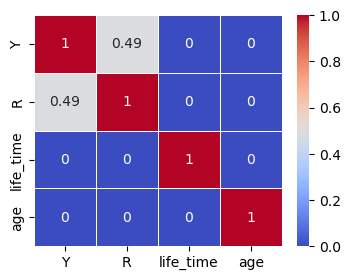

In [6]:
corr_data = df[[target] + features]

corr_matrix = np.round(corr_data.corr(),2)
corr_matrix[np.abs(corr_matrix)<=0.2] = 0

plt.figure(figsize=(4, 3))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths= 0.5);

In [7]:
X_train = df[df['month']<11][features]
y_train = df[df['month']<11][target]
X_test = df[df['month']==11][features]
y_test = df[df['month']==11][target]

In [8]:
scaler = StandardScaler()

colnames = X_train.columns
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=colnames)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=colnames)

In [9]:
logreg = LogisticRegression(solver='liblinear')
logreg.fit(X_train_scaled, y_train)

print('classes', logreg.classes_)
print('intercept ', logreg.intercept_[0])
pd.DataFrame({'coeff': logreg.coef_[0]}, index=colnames)

classes [0 1]
intercept  2.6507367506560118


,coeff
R,6.180465
life_time,-0.290732
age,-0.026484


In [10]:
yhat = logreg.predict(X_test_scaled)

In [11]:
pred_prob = pd.DataFrame(logreg.predict_proba(X_test_scaled))
# pred_prob

## <font color = DarkGreen size = 5> <b>Бинарная классификация</b> </font>

### <font color = MediumBlue size = 4> <b>Матрица ошибок (confusion matrix)</b> </font>

<u>**Матрица ошибок**</u> — это таблица, показывающая число правильных и неправильных предсказаний, сгруппированных по типу отклика.

Класс, который представляет для нас интерес, называется «положительным», а оставшийся — «отрицательным».

Для каждого объекта в выборке возможно 4 ситуации:
- предсказали положительную метку и угадали - **true positive (TP)** \
    True - предсказали правильно, positive — предсказали положительную метку
- предсказали положительную метку, но ошиблись - **false positive (FP)** \
    False — предсказание было неправильным
- предсказали отрицательную метку и угадали - **true negative (TN)**
- предсказали отрицательную метку, но ошиблись - **false negative (FN)**

Для удобства все эти 4 числа изображают в виде таблицы, которую называют **confusion matrix (матрицей ошибок)**

<img src="./img/01.png" width="600"/>

In [12]:
cm = confusion_matrix(y_test, yhat)
TN, FP, FN, TP = cm.ravel()
TN, FP, FN, TP

(446, 0, 39, 515)

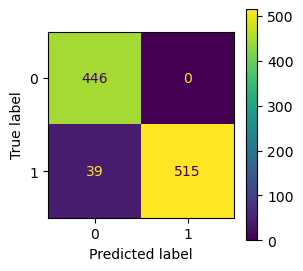

In [13]:
fig, ax = plt.subplots(figsize=(3, 3))
cm_display = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = [0, 1])
cm_display.plot(ax=ax);

#### <font color = SteelBlue size = 3> <b>Accuracy</b> </font>

**Accuracy** - показывает долю правильных классификаций.\
Accuracy характеризует качество модели, агрегированное по всем классам.

$\displaystyle \text{Accuracy} = \frac{TP+TN}{TP+TN+FP+FN}$

#### <font color = SteelBlue size = 3> <b>Error rate (доля ошибочных классификаций)</b> </font>

$\displaystyle \text{Error rate} = \frac{FP+FN}{TP+TN+FP+FN} = 1 - Accuracy$

`-` не учитывает дисбаланс классов\
`-` не учитывает цену ошибки на объектах разных классов

In [14]:
accuracy = accuracy_score(y_test, yhat)
er = 1 - accuracy
print(f"""
  Accuracy = {accuracy}
Error rate = {er:.3f}
""")


  Accuracy = 0.961
Error rate = 0.039



#### <font color = SteelBlue size = 3> <b>Precision (точность)</b> </font>

В случае ассиметрии классов, можно использовать метрики, которые не учитывают TN и ориентируются на TP.

Если мы рассмотрим долю правильно предсказанных положительных объектов среди всех объектов, предсказанных положительным классом, то мы получим метрику, которая называется **точностью (precision)**

**Precision** - показывает долю верно классифицированных объектов среди всех объектов, которые к этому классу отнес классификатор.

$\displaystyle Precision = \frac{TP}{TP+FP}$

#### <font color = SteelBlue size = 3> <b>Recall (полнота) / TPR (true positive rate)</b> </font>

Если же мы рассмотрим долю правильно найденных положительных объектов среди всех объектов положительного класса, то мы получим метрику, которая называется **полнотой (recall)**

**Recall (sensitivity, TPR)** - показывает отношение верно классифицированных объектов класса к общему числу элементов этого класса.

$\displaystyle Recall = \frac{TP}{TP+FN}$

<img src="./img/02.png" width="800"/>

In [15]:
precision = precision_score(y_test, yhat)
TPR = recall_score(y_test, yhat)
print(f"""
Precision = {precision}
   Recall = {TPR:.3f}
""")


Precision = 1.0
   Recall = 0.930



#### <font color = SteelBlue size = 3> <b>Specificity (специфичность)</b> </font>

**Specificity** - показывает отношение верных срабатываний классификатора к общему числу объектов за пределами класса.\
Иначе говоря, то, насколько часто классификатор правильно НЕ относит объекты к классу.

$Specificity = \cfrac{TN}{FP+TN}$

#### <font color = SteelBlue size = 3> <b>Fall-out / FPR</b> </font>

**Fall-out** (**FPR** (false positive rate)) - показывает долю неверных срабатываний классификатора к общему числу объектов за пределами класса.\
Иначе говоря то, насколько часто классификатор ошибается при отнесении того или иного объекта к классу.

$FPR = \cfrac{FP}{FP+TN}$


In [16]:
specificity = TN / (TN + FP)
FPR = FP / (TN + FP)
print(f"""
Specificity = {specificity}
   Fall-out = {FPR}
""")


Specificity = 1.0
   Fall-out = 0.0



#### <font color = SteelBlue size = 3> <b>F1-мера</b> </font>

Модели очень удобно сравнивать, когда их качество выражено одним числом.\
В случае пары Precision-Recall существует популярный способ скомпоновать их в одну метрику - взять их среднее гармоническое.\
Данный показатель эффективности носит название **F1-меры (F1-measure)**.

$\displaystyle F1 = \frac{2}{\cfrac{1}{Recall} + \cfrac{1}{Precision}} = 2 \frac{Recall \cdot Precision}{Recall + Precision} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}$

F1-мера предполагает одинаковую важность Precision и Recall.

<br>

Если одна из этих метрик приоритетнее, то можно воспользоваться $F_\beta$ мерой (среднее гармоническое взвешенное):\
$F_\beta = (\beta^2 + 1) \cfrac{Recall \cdot Precision}{Recall + \beta^2 Precision} = \cfrac{(1 + \beta^2) \cdot TP}{(1 + \beta^2) \cdot TP + FP + \beta^2 FN}$

- Если установить значение $\beta > 1$, это придаст большее значение Recall при оценке производительности модели;
- Если установить значение $\beta < 1$, это придаст большее значение Precision;
- Значение $\beta = 1$, обеспечивает идеальный баланс между Precision и Recall.

In [17]:
F1 = f1_score(y_test, yhat)
print(f"F1-мера = {F1:.4f}")

F1-мера = 0.9635


In [18]:
b = 2
Fb = fbeta_score(y_test, yhat, beta=b)
print(f"F-beta мера = {Fb:.4f}")

F-beta мера = 0.9429


#### <font color = SteelBlue size = 3> <b>Индекс Фоулкса–Мэллова (Fowlkes–Mallows index)</b> </font>

Геометрическое среднее Precision и Recall

$FM = \sqrt{\cfrac{TP}{TP+FP} \cdot \cfrac{TP}{TP+FN}}$\
.

In [19]:
FM = np.sqrt(precision*TPR)
print(f"Индекс Фоулкса–Мэллова = {FM:.4f}")

Индекс Фоулкса–Мэллова = 0.9642


In [20]:
for p, r in [(0.05, 1), (0.525,0.525), (0.2,1), (0.2,0.3)]:
    f1 = 2*p*r/(p+r)
    fm = np.sqrt(p*r)
    print(f"precision = {p:>6} |  recall = {r:>6} |  F1 = {f1:.4f} |  FM = {fm:.4f}")

precision =   0.05 |  recall =      1 |  F1 = 0.0952 |  FM = 0.2236
precision =  0.525 |  recall =  0.525 |  F1 = 0.5250 |  FM = 0.5250
precision =    0.2 |  recall =      1 |  F1 = 0.3333 |  FM = 0.4472
precision =    0.2 |  recall =    0.3 |  F1 = 0.2400 |  FM = 0.2449


### <font color = MediumBlue size = 4> <b>Вероятности классов</b> </font>

Многие модели бинарной классификации устроены так, что класс объекта получается бинаризацией выхода классификатора по некоторому фиксированному порогу:

$f(x;w,w_0) = \mathbb{I}[g(x,w) > w_0]$

Если целью является построение прогноза в терминах метки класса, то нужно учесть, что в зависимости от порога мы будем получать разные предсказания и разное качество на отложенной выборке.\
Чем ниже порог отсечения, тем больше объектов модель будет относить к положительному классу.

#### <font color = SteelBlue size = 3> <b>AUC</b> </font>

Пусть мы хотим учитывать ошибки на объектах обоих классов.\
При уменьшении порога отсечения мы будем находить (правильно предсказывать) всё большее число положительных объектов, но также и неправильно предсказывать положительную метку на всё большем числе отрицательных объектов.

Пусть алгоритм выдал оценки, которые мы упорядочим по убыванию ответов алгоритма.

In [21]:
df = pd.DataFrame({'id': range(1,8),
                   'score': [0.5, 0.1, 0.2, 0.6, 0.2, 0.3, 0.0],
                   'class': [0, 0, 0, 1, 1, 1, 0]})
df.sort_values('score', ascending=False, inplace=True)
df

,id,score,class
3,4,0.6,1
0,1,0.5,0
5,6,0.3,1
2,3,0.2,0
4,5,0.2,1
1,2,0.1,0
6,7,0.0,0


В идеале столбец `class` тоже станет упорядочен (сначала 1, потом 0); в самом худшем случае – порядок будет обратный (сначала 0, потом 1); в случае «слепого угадывания» будет случайное распределение 0 и 1.

Чтобы нарисовать ROC-кривую, надо взять единичный квадрат на координатной плоскости, разбить его на m равных частей горизонтальными линиями и на n – вертикальными, где m – число 1 среди правильных меток теста, n – число нулей.\
В результате квадрат разбивается сеткой на $m \times n$ блоков.

Теперь будем просматривать строки сверху вниз и прорисовывать на сетке линии, переходя их одного узла в другой.\
Стартуем из точки (0, 0).\
Если значение метки класса в просматриваемой строке 1, то делаем шаг вверх; если 0, то делаем шаг вправо.\
Если у нескольких объектов значения оценок равны, то мы делаем шаг в точку, которая на $a$ блоков выше и $b$ блоков правее (где $a$ – число единиц в группе объектов с одним значением метки, $b$ – число нулей в ней).\
В итоге мы попадём в точку (1, 1), т.к. сделаем в сумме $m$ шагов вверх и $n$ шагов вправо.

<img src="./img/03.png" width="400"/>

#### <font color = SteelBlue size = 3> <b>AUC ROC</b> </font>

Чем лучше классификатор разделяет два класса, тем больше площадь (area under curve) под ROC-кривой - и мы можем использовать её в качестве метрики.

Идеальному соответствует ROC-кривая, проходящая через точку (0, 1), площадь под ней равна 1\
Наихудшему – ROC-кривая, проходящая через точку (1, 0), площадь под ней – 0\
Случайному – что-то похожее на диагональ квадрата, площадь примерно равна 0.5

Сетка разбила квадрат на $m \times n$ блоков.\
Столько же пар вида (объект класса 1, объект класса 0), составленных из объектов тестовой выборки.\
Каждый закрашенный блок соответствует паре (объект класса 1, объект класса 0), для которой наш алгоритм правильно предсказал порядок (объект класса 1 получил оценку выше, чем объект класса 0), незакрашенный блок – паре, на которой ошибся.

<img src="./img/04.png" width="200"/>

**AUC ROC равен доле пар объектов вида (объект класса 1, объект класса 0), которые алгоритм верно упорядочил, то есть предсказание классификатора на первом объекте больше**

$\cfrac{\displaystyle \sum_{i=1}^{q} \sum_{j=1}^{q} {\mathbb{I}[y_i < y_j] \mathbb{I}'[a_i < a_j]}}{\displaystyle \sum_{i=1}^{q} \sum_{j=1}^{q} {\mathbb{I}[y_i < y_j]}}$

$\mathbb{I}'[a_i < a_j] =
\begin{cases}
0, & \quad a_i > a_j\\
0.5, & \quad a_i = a_j\\
1, & \quad a_i < a_j
\end{cases}
\quad$
$\quad \mathbb{I}[y_i < y_j] =
\begin{cases}
0, & \quad y_i \geq y_j\\
1, & \quad y_i < y_j
\end{cases}$

.

На практике нам часто надо будет решить: какие объекты отнести к классу 1, а какие к классу 0.\
Для этого нужно будет выбрать порог отсечения (объекты с оценками выше порога считаем принадлежащими классу 1, остальные – 0).

Выбору порога соответствует выбор точки на ROC-кривой.\
Например, для порога 0.25 и нашего примера – точка (1/4, 2/3).

<img src="./img/05.png" width="200"/>

1/4 – это процент точек класса 0, которые неверно классифицированы нашим алгоритмом (FPR),\
2/3 – процент точек класса 1, которые верно классифицированы нашим алгоритмом (TPR).\
Именно в этих координатах (FPR, TPR) построена ROC-кривая.

**TPR (true positive rate)** - это полнота, доля положительных объектов, правильно предсказанных положительными:\
$TPR = \cfrac{TP}{TP+FN}$

**FPR (false positive rate)** - это доля отрицательных объектов, неправильно предсказанных положительными:\
$FPR = \cfrac{FP}{FP+TN}$

[интерактивный график](https://yastatic.net/s3/academy/ml/roc_auc/roc.html)

Желтая и синяя кривые показывают распределение предсказаний классификатора на объектах положительного и отрицательного классов соответственно.
- Если классификатор идеальный (две кривые разделимы по оси X), то на правом графике получаем ROC-кривую (0,0)->(0,1)->(1,1), площадь под которой равна 1
- Если классификатор случайный (предсказывает одинаковые метки положительным и отрицательным объектам), то получаем ROC-кривую (0,0)->(1,1), площадь под которой равна 0.5

In [22]:
fpr, tpr, thresholds = roc_curve(y_test, pred_prob[1])
# fpr, tpr, thresholds

In [23]:
roc_auc = auc(fpr, tpr)
roc_auc

0.9810954978873582

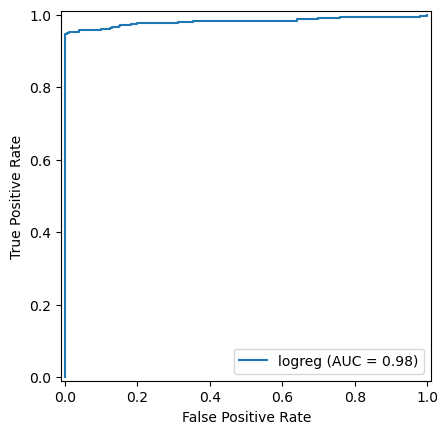

In [25]:
RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='logreg').plot();

#### <font color = SteelBlue size = 3> <b>PR ROC</b> </font>

**PR-кривая** показывает компромисс между точностью (Precision) и полнотой (Recall) при разных порогах классификации.

- По оси X — Recall, по оси Y — Precision.
- Чем ближе кривая к правому верхнему углу, тем лучше модель.
- Площадь под кривой (Average Precision, AP) — интегральная метрика качества (чем ближе к 1, тем лучше).
- Особенно полезна при несбалансированных данных, когда отрицательных примеров намного больше, чем положительных.

Когда использовать?
- Если классы сильно несбалансированы.
- Если важнее минимизировать False Positives (например, в спам-фильтрах).

#### <font color = SteelBlue size = 3> <b>AUC-PR (Area Under Precision-Recall Curve)</b> </font>

**AUC-PR** — это интегральная метрика, которая оценивает качество модели бинарной классификации, вычисляя площадь под Precision-Recall (PR) кривой. В отличие от AUC-ROC, она более чувствительна к дисбалансу классов и полезна, когда положительные примеры редки.

$AUC-PR = \int_{0}^{1} Precision(Recall) \; \mathrm{d}Recall$

**Когда выбирать AUC-PR?**
- Если классы сильно несбалансированы (например, 1% положительных).
- Если False Positives критичны (например, в медицинской диагностике).
- В задачах поиска информации (IR), детекции объектов (mAP).

**Интерпретация AUC-PR**
- $AUC-PR > 0.9$ — отличное качество.
- $AUC-PR \sim 0.5-0.7$ — среднее.
- $AUC-PR < 0.3$ — плохое (хуже случайного, если классы сбалансированы).

**Пример для дисбалансированных данных**\
Допустим, положительных примеров всего 1%:
- Случайный классификатор даст $AUC-PR \approx 0.01$
- Хорошая модель должна стремиться к $AUC-PR > 0.5$

In [26]:
precision, recall, thresholds = precision_recall_curve(y_test, pred_prob[1])
# precision, recall, thresholds

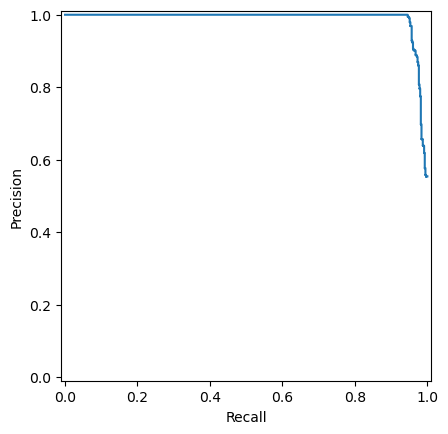

In [27]:
PrecisionRecallDisplay(precision=precision, recall=recall).plot();

**Average Precision (AP)** — это метрика, которая агрегирует Precision-Recall (PR) кривую в одно число, характеризующее качество модели бинарной классификации, особенно на несбалансированных данных.

PR-кривая показывает, как меняется точность (Precision) при увеличении полноты (Recall).

AP — это площадь под PR-кривой, но на практике вычисляется как усреднённая точность по всем возможным уровням полноты.

Для набора порогов классификации вычисляется Precision и Recall, затем AP рассчитывается как:\
$AP = \displaystyle \sum_{k=1}^{n}{(Recall_k - Recall_{k-1}) \cdot Precision_k}$\
$k$ - точка на PR-кривой (например, при изменении порога классификации)\
$Precision_k$ - точность в точке $k$\
$Recall_k - Recall_{k-1}$ - прирост полноты

**Интерпретация AP**:
- $AP = 1$ — идеальная модель (все положительные примеры ранжированы выше отрицательных).
- $AP \approx 0$ — модель работает хуже случайного угадывания.
- Чем ближе AP к 1, тем лучше модель отделяет положительные примеры от отрицательных.

**Связь между AUC-PR и Average Precision (AP)**
AP (Average Precision) — это дискретный аналог AUC-PR, вычисляемый как взвешенная сумма Precision на разных уровнях Recall.\
В большинстве случаев AP $\approx$ AUC-PR, но:
- AP используется в object detection (mAP).
- AUC-PR — гладкая аппроксимация площади под PR-кривой.

В scikit-learn **average_precision_score** вычисляет AP как **взвешенную сумму Precision на разных уровнях Recall**.

**Когда использовать AP?**
- Несбалансированные данные (например, 1% положительных классов).
- Задачи ранжирования (поиск информации, рекомендательные системы).
- Детекция объектов (mAP — mean Average Precision).

**Average Precision (AP)** — мощная метрика для задач, где важно **качество предсказания положительного класса** (например, поиск аномалий, детекция объектов). Она лучше AUC-ROC на несбалансированных данных, так как фокусируется на **Precision и Recall**, а не на True Negative Rate.

In [28]:
average_precision_score(y_test, pred_prob[1])

0.9896746262536621

**Сравнение PR и ROC**

| Критерий | PR-кривая | ROC-кривая |
| --- | --- | --- |
| Оси | Precision (Y) vs Recall (X) | TPR (Y) vs FPR (X) |
| Чувствительность | Лучше для несбалансированных данных | Устойчива к дисбалансу |
| Фокус | На положительном классе | На обоих классах |
| Метрика | Average Precision (AP) | AUC-ROC |
| Использование | Когда FP важны (спам, медицина) | Общая оценка классификации |

**Сравнение AUC-PR и AUC-ROC**

| Критерий | AUC-PR | AUC-ROC |
| --- | --- | --- |
| Оси |Precision (Y) - Recall (X) | TPR (Y) - FPR (X) |
| Чувствительность | Лучше для несбалансированных данных | Устойчива к дисбалансу |
| Фокус |  На положительном классе | На обоих классах |
| Случайный уровень | $\approx$ доле положительных классов | 0.5 |
| Использование |  Медицина, аномалии, редкие классы | Общая оценка классификации |